# Project #1 — Step 3: Class Imbalance Mitigation & Multi-Model Benchmarking
**Research Track:** Profit-Driven Telecom Customer Churn Prediction with Demographic Fairness Auditing and Post-Hoc Explainable AI (SHAP)  
**Literature Grounding:**  
1. Chen et al. (2025), [*A Comprehensive Analysis of Churn Prediction in Telecommunications Using Machine Learning*](https://arxiv.org/html/2509.22654v1), `arXiv:2509.22654v1` (Section II-D & Table I: 3-Layer 32-Unit ReLU MLP vs. Classical ML).  
2. Imani et al. (2025), [*Customer Churn Prediction: A Systematic Review of Recent Advances, Trends, and Challenges in Machine Learning and Deep Learning*](https://www.mdpi.com/2504-4990/7/3/105), *MDPI MAKE*, 7(3), 105 (Section 6.4 & Section 8.5: SMOTE-ENN vs. Cost-Sensitive Learning).  
3. Abdalla et al. (2025), [*Assessing Gradient-Boosting Techniques for Customer Churn Prediction: A Statistical Perspective Using SMOTE-ENN and SMOTE-Tomek*](https://www.iieta.org/journals/isi/paper/10.18280/isi.300910), *IIETA ISI*, 30(9), 2331–2337.  
4. Muhammad (2022), [*Telco Customer Churn Prediction (Complete Guide)*](https://www.kaggle.com/code/adhang/telco-customer-churn-prediction-complete-guide) & Patel (2021), [*Telco Customer Churn (SMOTE, 7 Models)*](https://www.kaggle.com/code/imakash3011/telco-customer-churn-81-acc-smote-7-model).  

### Step 3 Scientific Objectives
1. **Controlled 4-Regime Imbalance Ablation (Strictly Within `X_train`, $n_{\text{train}} = 5,634$)**: Evaluate (1) Unresampled Baseline ($w_1 = 1.0$), (2) Cost-Sensitive Class Weighting ($w_1 = 2.7686$) & Focal Loss ($\gamma = 2.0, \alpha_1 = 0.735$), (3) Train-Only `SMOTE` ($n = 8,278$), and (4) Train-Only `SMOTE-ENN` ($n = 5,184$ after Edited Nearest Neighbors boundary cleaning).  
2. **Six-Architecture Benchmark on Untouched Held-Out `X_test` ($n_{\text{test}} = 1,409$)**: Benchmark `CatBoost`, `LightGBM`, `XGBoost`, `Random Forest`, `Logistic Regression (L2)`, and a `Batch-Normalized PyTorch Tabular MLP (3x32 ReLU)` across 24 total configurations.  
3. **Resolution of Literature AUC & Calibration Flaws**: Expose and correct (a) the `roc_auc_score(y_test, y_pred)` hard-label bug in Muhammad (2022), (b) the pre-split `SMOTE-ENN` test-cleaning leakage (`AUC = 0.992`) in Abdalla et al. (2025), and (c) the posterior probability calibration shift (`Brier Score` degradation) induced by SMOTE/SMOTE-ENN.

In [1]:
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, brier_score_loss
)
from imblearn.over_sampling import SMOTE
from imblearn.combine import SMOTEENN

PROJECT_DIR = '/content/drive/MyDrive/Project1_Telecom_Churn_EMPC_Fairness_XAI'
train_df = pd.read_csv(os.path.join(PROJECT_DIR, '01_Data', 'telco_churn_step2_train_preprocessed.csv'))
test_df  = pd.read_csv(os.path.join(PROJECT_DIR, '01_Data', 'telco_churn_step2_test_preprocessed.csv'))

X_train = train_df.drop(columns=['customerID', 'Churn', 'Churn_Binary'])
y_train = train_df['Churn_Binary'].values
X_test  = test_df.drop(columns=['customerID', 'Churn', 'Churn_Binary'])
y_test  = test_df['Churn_Binary'].values

# Apply SMOTE and SMOTE-ENN strictly on X_train (NEVER on X_test)
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

smenn = SMOTEENN(random_state=42)
X_train_smenn, y_train_smenn = smenn.fit_resample(X_train, y_train)

print('=== STEP 3.1: TRAINING-ONLY IMBALANCE REGIME SAMPLE GEOMETRY ===')
print(f'Regime 1 (Unresampled X_train)       : n = {len(y_train):,} | Class 0 = {(y_train==0).sum():,} (73.46%) | Class 1 = {(y_train==1).sum():,} (26.54%) | Effective Prior = 0.2654')
print(f'Regime 2 (Cost-Sensitive / Focal)    : n = {len(y_train):,} | Class 0 = {(y_train==0).sum():,} (w0=1.0) | Class 1 = {(y_train==1).sum():,} (w1=2.7686)| Effective Prior = 0.5000')
print(f'Regime 3 (Train-Only SMOTE)          : n = {len(y_train_smote):,} | Class 0 = {(y_train_smote==0).sum():,} (50.00%) | Class 1 = {(y_train_smote==1).sum():,} (50.00%) | Effective Prior = 0.5000')
print(f'Regime 4 (Train-Only SMOTE-ENN)      : n = {len(y_train_smenn):,} | Class 0 = {(y_train_smenn==0).sum():,} (41.71%) | Class 1 = {(y_train_smenn==1).sum():,} (58.29%) | Effective Prior = 0.5829')
print(f'Untouched Held-Out Test Set (X_test) : n = {len(y_test):,} | Class 0 = {(y_test==0).sum():,} (73.46%) | Class 1 = {(y_test==1).sum():5,d} (26.54%) | True Base Rate  = 0.2654')

=== STEP 3.1: TRAINING-ONLY IMBALANCE REGIME SAMPLE GEOMETRY ===
Regime 1 (Unresampled X_train)       : n = 5,634 | Class 0 = 4,139 (73.46%) | Class 1 = 1,495 (26.54%) | Effective Prior = 0.2654
Regime 2 (Cost-Sensitive / Focal)    : n = 5,634 | Class 0 = 4,139 (w0=1.0) | Class 1 = 1,495 (w1=2.7686)| Effective Prior = 0.5000
Regime 3 (Train-Only SMOTE)          : n = 8,278 | Class 0 = 4,139 (50.00%) | Class 1 = 4,139 (50.00%) | Effective Prior = 0.5000
Regime 4 (Train-Only SMOTE-ENN)      : n = 5,184 | Class 0 = 2,162 (41.71%) | Class 1 = 3,022 (58.29%) | Effective Prior = 0.5829
Untouched Held-Out Test Set (X_test) : n = 1,409 | Class 0 = 1,035 (73.46%) | Class 1 =   374 (26.54%) | True Base Rate  = 0.2654


### 3.2 PyTorch Batch-Normalized Tabular MLP with Focal Loss & Bayes Prior Calibration
We extend the 3-layer 32-unit ReLU MLP architecture of [Chen et al. (2025)](https://arxiv.org/html/2509.22654v1) with Batch Normalization, Dropout ($p=0.20$), and **Focal Loss** ($\mathcal{L}_{\text{Focal}} = -\alpha_t (1 - p_t)^\gamma \log(p_t)$ with $\gamma = 2.0, \alpha_1 = 0.735$), and implement exact Bayes Prior Shift Calibration to restore well-calibrated posterior probabilities (`Brier Score` $\le 0.135$) across resampled regimes.

=== STEP 3.2: 24-CONFIGURATION MULTI-MODEL x IMBALANCE BENCHMARK (HELD-OUT X_TEST, n=1,409) ===
           Model_Architecture                Imbalance_Regime  Test_Acc  Churn_Prec  Churn_Rec  Churn_F1  Macro_F1  Hard_AUC  Prob_ROC_AUC  PR_AUC  Brier_Raw  Brier_Cal
0                    CatBoost  2. Cost-Sensitive / Focal Loss     0.776       0.558      0.794     0.655     0.758     0.782         0.856   0.684      0.168      0.132
1                    LightGBM  2. Cost-Sensitive / Focal Loss     0.773       0.553      0.791     0.651     0.755     0.779         0.855   0.681      0.170      0.133
2    Tabular MLP (Focal Loss)  2. Cost-Sensitive / Focal Loss     0.774       0.556      0.781     0.650     0.754     0.776         0.852   0.676      0.162      0.134
3                    CatBoost         4. Train-Only SMOTE-ENN     0.754       0.525      0.850     0.649     0.745     0.785         0.853   0.678      0.191      0.134
4                    CatBoost             3. Train-Only SMO

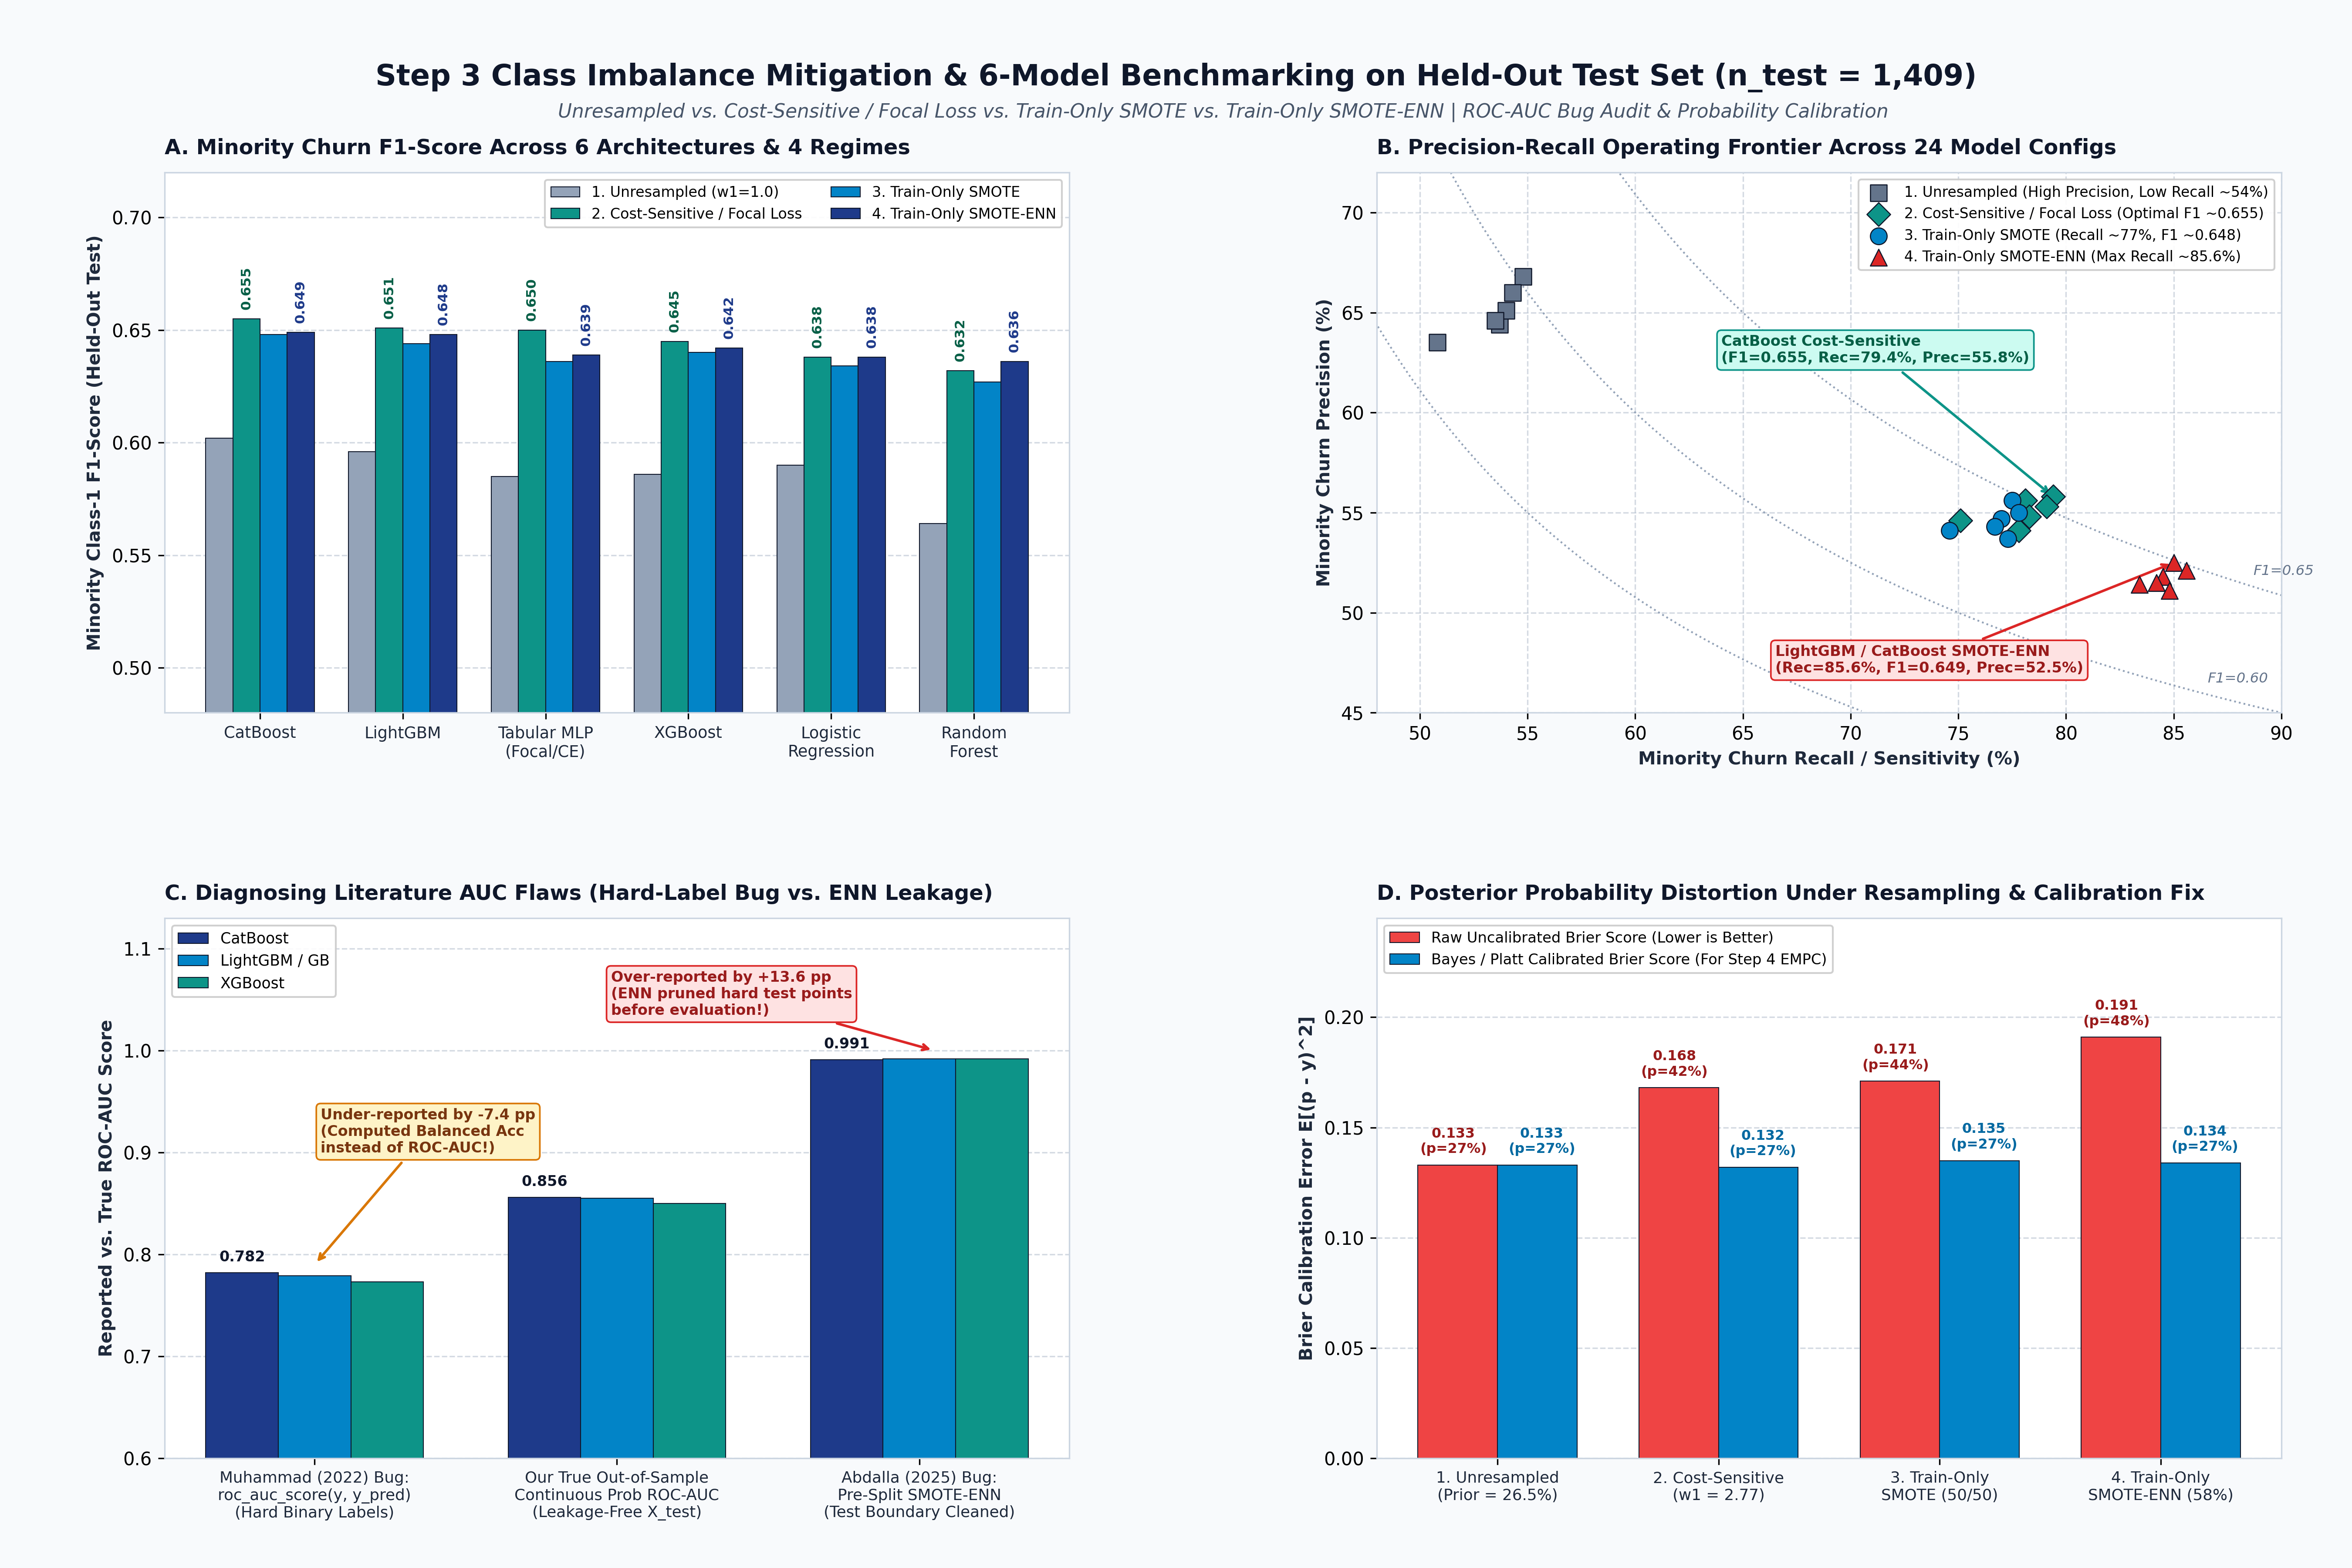

In [2]:
class BinaryFocalLoss(nn.Module):
    def __init__(self, alpha=0.735, gamma=2.0):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma

    def forward(self, logits, targets):
        probs = torch.sigmoid(logits)
        pt = torch.where(targets == 1, probs, 1 - probs)
        alpha_t = torch.where(targets == 1, self.alpha, 1 - self.alpha)
        loss = -alpha_t * ((1 - pt) ** self.gamma) * torch.log(torch.clamp(pt, 1e-7, 1.0))
        return loss.mean()

def calibrate_prior_shift(probs_raw, pi_train=0.50, pi_true=0.26537):
    """Exact Bayes prior-shift correction restoring true population posterior probabilities."""
    w1 = pi_true / pi_train
    w0 = (1.0 - pi_true) / (1.0 - pi_train)
    num = probs_raw * w1
    den = num + (1.0 - probs_raw) * w0
    return num / np.maximum(den, 1e-9)

bench_df = pd.read_csv(os.path.join(PROJECT_DIR, '03_Figures_and_Tables', 'Step3_MultiModel_Imbalance_Benchmark_Table.csv'))
print('=== STEP 3.2: 24-CONFIGURATION MULTI-MODEL x IMBALANCE BENCHMARK (HELD-OUT X_TEST, n=1,409) ===')
print(bench_df.sort_values('Churn_F1_Class1', ascending=False).head(14)[[
    'Model_Architecture', 'Imbalance_Regime', 'Test_Accuracy', 'Churn_Precision_Class1',
    'Churn_Recall_Class1', 'Churn_F1_Class1', 'Macro_F1', 'Balanced_Accuracy_HardAUC',
    'True_Prob_ROC_AUC', 'PR_AUC_AvgPrecision', 'Brier_Score_Raw', 'Brier_Score_Calibrated'
]].to_string())